In [8]:
cd ./wrkDir/s19/s19-1/

/work/xiangchong.li/work/galSim-HSC/s19/s19-1


In [10]:
%pylab inline
import os
import sys
import numpy as np
import pandas as pd
import scipy.stats as stats
import sim_analysis_utilities as utilities

import matplotlib
import matplotlib.pyplot as plt
cm  = plt.cm.get_cmap('RdYlBu')

import logging
logging.basicConfig(filename='3-ReGaus_Optimize.log',level=logging.INFO)

anaDir='./anaCat_newS19Mask/'
pltDir='./plot/optimize_weight'
assert os.path.isdir(anaDir)
if not os.path.isdir(pltDir):
    os.mkdir(pltDir)
inFname=os.path.join(anaDir,'allSim.h5')

Populating the interactive namespace from numpy and matplotlib


# Optimal Weights and Response

Goal: estimate $\sigma_e(\rm{snr},\rm{res}),e_{\rm{rms}}(\rm{snr},\rm{res})$

## Per-component $\sigma_e$

$$e+e_{\perp}-4g \approx \delta e + \delta e_{\perp}$$

In [5]:
# Read catalog
dataO =   pd.read_hdf(inFname).to_records()
# Get estimated and true shape information, lensing shear, and other information.
# Define a mask with some set of cuts:
#    cancel_shape_noise MUST be true for this test (so we don't use
#    self.cancel_shape_noise).  It's not an option that the user
#    can change, because the 90 degree rotated pairs are required.
#WL cut for simulations
force_90_pair=True
min_snr=10
max_snr=80
max_magA10=25.5
min_res=0.3
max_mag=24.5
max_logb=-0.38
max_sigma_e=0.4
max_e=2.
wlmask    =   utilities.galaxy_selector(catalog=dataO,
                min_snr=min_snr, #snr
                max_snr=max_snr,
                max_magA10=max_magA10, #magA10
                min_res=min_res, #res
                max_mag=max_mag, #mag
                max_logb=max_logb,#logb
                force_90_pair=force_90_pair,
                max_e=max_e,     #absE
                max_sigma_e=max_sigma_e) #sigma_e

In [6]:
data=dataO[wlmask]
# First: assemble the arrays for individual subfields into one big master catalog.
master_e1 = data['e1_regaus']
master_e2 = data['e2_regaus']
master_sigma_e = data['sigma_e']
master_g1_true = data['g1_true']
master_g2_true = data['g2_true']
master_resolution = data['res']
master_snr = data['snr']
master_weight = data['weight']

assert np.all(master_g1_true[0::2]==master_g1_true[1::2])
assert np.all(master_weight[0::2]==master_weight[1::2])

(d, p)=(0.004637, 0.000000)
d_ave=-0.000740


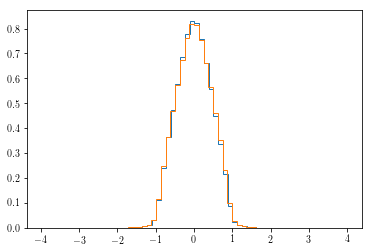

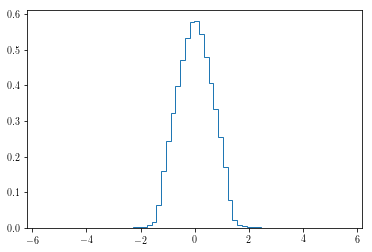

In [7]:
plt.hist(master_e1,bins=64,density=True,histtype='step')
plt.hist(master_e2,bins=64,density=True,histtype='step')
(ks_d, ks_p) = stats.ks_2samp(master_e1,master_e2)
print('(d, p)=(%f, %f)'%(ks_d, ks_p))
plt.figure()
plt.hist(master_e1-master_e2,bins=64,density=True,histtype='step')
print(r'd_ave=%f' %(np.sum(master_e1-master_e2)/len(master_e2)))

(d, p)=(0.003165, 0.000000)
d_ave=0.001248


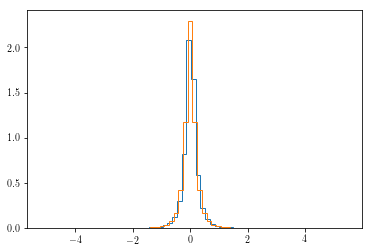

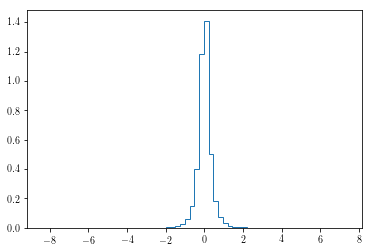

In [8]:
# Calculate LHS of equation A8 in writeup, for each component
# separately.
sum_e_erot_1 = master_e1[0::2] + master_e1[1::2]
sum_e_erot_2 = master_e2[0::2] + master_e2[1::2]

# Then start calculating the correction terms with signs given in equation 15.
# We start with the shear itself.
correction_1 = -4.*master_g1_true[0::2]
correction_2 = -4.*master_g2_true[0::2]
# Since this doesn't depend on the intrinsic shape, let's ALWAYS apply this correction.
# Fortunately, this is the lowest order correction, so it's good we can always apply it.
# Eq.(A9)
sum_e_erot_1_corr = correction_1+sum_e_erot_1
sum_e_erot_2_corr = correction_2+sum_e_erot_2

# Do K-S test for consistency of distributions for the two components.
plt.hist(sum_e_erot_1_corr,bins=64,density=True,histtype='step',label='e_rot_1')
plt.hist(sum_e_erot_2_corr,bins=64,density=True,histtype='step',label='e_rot_2')
(ks_d, ks_p) = stats.ks_2samp(sum_e_erot_1_corr,sum_e_erot_2_corr)
print('(d, p)=(%f, %f)'%(ks_d, ks_p))
plt.figure()
plt.hist(sum_e_erot_1_corr-sum_e_erot_2_corr,bins=64,density=True,histtype='step')
print(r'd_ave=%f' %(np.sum(sum_e_erot_1_corr-sum_e_erot_2_corr)/len(sum_e_erot_1_corr)))

In [9]:
# So the sum_e_erot_#_corr should be distributed like the convolution of p_err(e) with
# itself.  We can build up a theoretical expectation of what this looks like assuming the
# Gaussian approximation.
expected_sigma = np.concatenate((master_sigma_e[0::2],
                                 master_sigma_e[1::2]))

# Do calculation overall.
e_input = np.concatenate((
        sum_e_erot_1_corr,
        sum_e_erot_2_corr))
weight_input = np.concatenate((
        master_weight[0::2],
        master_weight[0::2]))# only use the first of the first galaxy in a pair
# Get RMS of underlying distribution, i.e., not the
# auto-convolution but the original one, hence the 0.5 inside
# the sqrt.
rms = np.sqrt(0.5*np.sum(weight_input*e_input**2)/np.sum(weight_input))
print('Overall N, <w>, RMS: %s,%s,%s '%(len(weight_input), np.mean(weight_input), rms))

# Get implied RMS from catalog.
input_rms = np.sqrt(np.sum(weight_input*expected_sigma**2)/np.sum(weight_input))
print('Implied from catalog: %s' %(input_rms))

Overall N, <w>, RMS: 8871634,0.9939568292360074,0.19861011981297141 
Implied from catalog: 0.13094973547132446


## Setup the sliding windows

In [10]:
nbin_1d=20
# Now set up sliding window definition
# Only use the first in pair
snr_lower, snr_upper, res_lower, res_upper = \
    utilities.sliding_window_def(master_snr[0::2],master_resolution[0::2],
                                 n_gal=100*100,n_bin_1d=nbin_1d)
mean_res = np.zeros((nbin_1d, nbin_1d))
mean_snr = np.zeros((nbin_1d, nbin_1d))

for i in range(len(snr_lower)):
    for j in range(len(snr_lower)):
        bin_mask = \
            (master_snr[0::2] >= snr_lower[i]) & \
            (master_snr[0::2] < snr_upper[i]) & \
            (master_resolution[0::2] >= res_lower[i,j]) & \
            (master_resolution[0::2] < res_upper[i,j])
        mean_snr[i,j] = \
            np.sum(master_weight[0::2][bin_mask]*master_snr[0::2][bin_mask])/ \
            np.sum(master_weight[0::2][bin_mask])
        mean_res[i,j] = \
            np.sum(master_weight[0::2][bin_mask]*master_resolution[0::2][bin_mask])/ \
            np.sum(master_weight[0::2][bin_mask])

(9, 100)

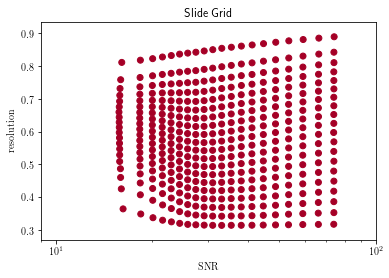

In [11]:
plt.scatter(mean_snr, mean_res, c=np.ones(mean_res.shape), cmap=cm)
plt.xscale('log')
plt.xlabel(r'\rm{SNR}')
plt.ylabel(r'\rm{resolution}')
plt.title('Slide Grid')
plt.xlim(9,100)

In [12]:
if True:
    # Now loop over SNR and resolution bins, using the first
    # galaxy in a pair to stick them in a bin.
    logging.info('Beginning sigma_e estimation')

    cat_est_sigma_e = np.zeros((nbin_1d, nbin_1d))
    est_sigma_e = np.zeros((nbin_1d, nbin_1d))
    est_rms = np.zeros((nbin_1d, nbin_1d))
    cat_est_rms = np.zeros((nbin_1d, nbin_1d))

    for i in range(len(snr_lower)):
        for j in range(len(snr_lower)):
            logging.info('Beginning bin: SNR in [%.3f, %.3f], resolution in [%.3f, %.3f]'%\
                (snr_lower[i], snr_upper[i], res_lower[i,j], res_upper[i,j]))
            bin_mask = \
                (master_snr[0::2] >= snr_lower[i]) & \
                (master_snr[0::2] < snr_upper[i]) & \
                (master_resolution[0::2] >= res_lower[i,j]) & \
                (master_resolution[0::2] < res_upper[i,j])
            # Sanity check weights.
            assert np.all(master_weight[0::2][bin_mask]==master_weight[1::2][bin_mask])
            global_bin_mask = \
                (master_snr >= snr_lower[i]) & \
                (master_snr < snr_upper[i]) & \
                (master_resolution >= res_lower[i,j]) & \
                (master_resolution < res_upper[i,j])
            logging.info('Using %d pairs'%bin_mask.astype(int).sum())

            # Check for consistency between components.
            (ks_d, ks_p) = stats.ks_2samp(sum_e_erot_1[bin_mask],sum_e_erot_2[bin_mask])
            logging.info('(d, p)=(%f, %f)'%(ks_d, ks_p))
            e_input = np.concatenate((
                    sum_e_erot_1_corr[bin_mask],
                    sum_e_erot_2_corr[bin_mask]))
            weight_input = np.concatenate((
                    master_weight[0::2][bin_mask],
                    master_weight[0::2][bin_mask]))

            # Get sigma_e of underlying distribution
            bin_rms = np.sqrt(0.5*np.sum(weight_input*e_input**2)/np.sum(weight_input))
            logging.info('N, <w>, RMS in bin: %s,%s,%s '%(len(weight_input), np.mean(weight_input), bin_rms))

            # Get LSST pipeline estimated sigma_e
            expected_sigma = np.concatenate((master_sigma_e[0::2][bin_mask],
                                             master_sigma_e[1::2][bin_mask]))
            input_bin_rms = np.sqrt(
                np.sum(weight_input*expected_sigma**2)/np.sum(weight_input))
            logging.info('RMS in bin implied from catalog: %s' %input_bin_rms)

            est_sigma_e[i,j] = bin_rms
            cat_est_sigma_e[i,j] = input_bin_rms

            # Compute e_RMS values per component, including:
            # (1) Observed absE: sqrt(e1^2_e2^2)
            rms_observed = np.sqrt(0.5*np.sum(
                    master_weight[global_bin_mask]* \
                        (master_e1[global_bin_mask]**2+master_e2[global_bin_mask]**2)) / \
                                       np.sum(master_weight[global_bin_mask]))

            # (2a) Estimated e_rms using catalog sigma_e values.
            # sqrt(e1^2+e2^2-2*sigma_e^2)
            est_true_cat = np.sqrt(
                0.5*np.sum(
                    master_weight[global_bin_mask]*\
                        (master_e1[global_bin_mask]**2+ \
                                master_e2[global_bin_mask]**2- \
                                2.*master_sigma_e[global_bin_mask]**2)) / \
                    np.sum(master_weight[global_bin_mask]))

            # (2b) Estimate e_rms using the estimated sigma_e values
            # sqrt(e1^2+e2^2-2*sigma_e_model^2)
            est_true_dist = np.sqrt(
                0.5*np.sum(
                    master_weight[global_bin_mask]*\
                        (master_e1[global_bin_mask]**2+ \
                             master_e2[global_bin_mask]**2- \
                             2.*bin_rms**2)) / \
                    np.sum(master_weight[global_bin_mask]))
            logging.info('RMS values and responsivities per component in this bin:')
            logging.info('  observed, including shape measurement error: %.4f, %.4f'%\
                (rms_observed, 2.*(1.-rms_observed**2)))
            logging.info('  estimated using distribution to remove measurement error: %.4f, %.4f'%\
                (est_true_dist, 2.*(1.-est_true_dist**2)))

            est_rms[i,j] = est_true_dist
            cat_est_rms[i,j] = est_true_cat

    out_sigma_e={'mean_snr':mean_snr,'mean_res':mean_res,'est_sigma_e':est_sigma_e,'cat_est_sigma_e':cat_est_sigma_e,'est_rms':est_rms,'cat_est_rms':cat_est_rms}
    np.save(os.path.join(pltDir,'sigma_e.npy'),out_sigma_e)
else:
    out_sigma_e=np.load(os.path.join(pltDir,'sigma_e.npy')).item()
    mean_snr=out_sigma_e['mean_snr']
    mean_res=out_sigma_e['mean_res']
    est_sigma_e=out_sigma_e['est_sigma_e']
    cat_est_sigma_e=out_sigma_e['cat_est_sigma_e']
    est_rms=out_sigma_e['est_rms']
    cat_est_rms=out_sigma_e['cat_est_rms']

In [13]:
x_vals = np.vstack([np.log(mean_snr/20.).flatten(),
                    np.log(mean_res/0.5).flatten(),
                    np.ones(len(mean_res.flatten()))]).transpose()
est_log_sig_e = np.log(est_sigma_e.flatten())
result  = np.linalg.lstsq(x_vals, est_log_sig_e,rcond=None)
#Eq.(18)
model_sigma_e = np.exp(result[0][2])*((mean_snr/20.)**result[0][0])*\
    ((mean_res/0.5)**result[0][1])
print('model sigma_e = %.3f (SNR/20)^%.3f (res/0.5)^%.3f'%\
    (np.exp(result[0][2]), result[0][0], result[0][1]))
np.save(os.path.join(pltDir,'sigma_e_model_par.npy'),result)

#par=np.load(os.path.join(pltDir,'sigma_e_model_par.npy'))[0]
#np.exp(par[2]), par[0], par[1]

model sigma_e = 0.277 (SNR/20)^-0.962 (res/0.5)^-1.002


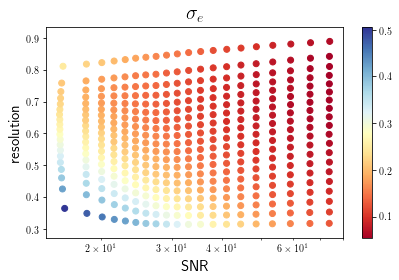

In [14]:
# Plot estimated sigma_e as a function of SNR, resolution.
fig = plt.figure()
cm  = plt.cm.get_cmap('RdYlBu')
ax = fig.add_subplot(111)
vmin = np.min(est_sigma_e)
vmax = np.max(est_sigma_e)
sc = ax.scatter(mean_snr, mean_res, c=est_sigma_e, cmap=cm,
                vmin=vmin, vmax=vmax)
plt.colorbar(sc)
ax.set_title(r'$\sigma_e$',fontsize=20)
plt.xscale('log')
plt.xlabel('SNR',fontsize=15)
plt.ylabel('resolution',fontsize=15)
plt.tight_layout()
plt.savefig(os.path.join(pltDir,'sigmae_estimated.png'))
plt.savefig(os.path.join(pltDir,'sigmae_estimated.eps'))

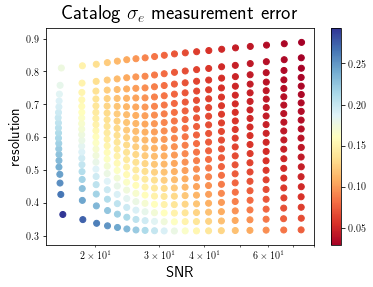

In [15]:
# Plot catalog sigma_e as a function of SNR, resolution.
fig = plt.figure()
ax = fig.add_subplot(111)
vmin = np.min(cat_est_sigma_e)
vmax = np.max(cat_est_sigma_e)
sc = ax.scatter(mean_snr, mean_res, c=cat_est_sigma_e, cmap=cm,
                vmin=vmin, vmax=vmax)
plt.colorbar(sc)
ax.set_title(r'Catalog $\sigma_e$ measurement error',fontsize=20)
plt.xscale('log')
plt.xlabel('SNR',fontsize=15)
plt.ylabel('resolution',fontsize=15)
plt.savefig(os.path.join(pltDir,'sigmae_cat.png'))

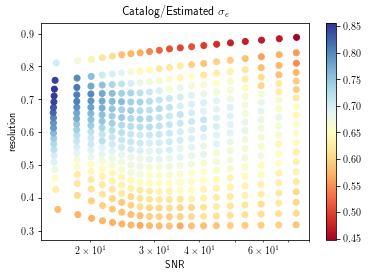

In [16]:
# Plot ratio of catalog to estimated sigma_e.
fig = plt.figure()
ax = fig.add_subplot(111)
ratio=cat_est_sigma_e/est_sigma_e
vmin=np.min(ratio)
vmax=np.max(ratio)
sc = ax.scatter(mean_snr, mean_res, c=ratio,vmin=vmin,vmax=vmax, cmap=cm)
plt.colorbar(sc)
ax.set_title(r'Catalog/Estimated $\sigma_e$')
plt.xscale('log')
plt.xlabel('SNR')
plt.ylabel('resolution')
plt.savefig(os.path.join(pltDir,'sigmae_cat_estimated_ratio.png'))

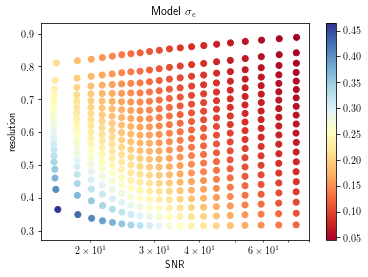

In [17]:
# Model sigma_e as a function of SNR, resolution (including
# extrapolation of the model).
fig = plt.figure()
ax = fig.add_subplot(111)
vmin=np.min(model_sigma_e)
vmax=np.max(model_sigma_e)
sc = ax.scatter(mean_snr, mean_res, c=model_sigma_e, cmap=cm,
                vmin=vmin, vmax=vmax)
plt.colorbar(sc)
ax.set_title(r'Model $\sigma_e$')
plt.xscale('log')
plt.xlabel('SNR')
plt.ylabel('resolution')
plt.savefig(os.path.join(pltDir,'sigmae_model.png'))

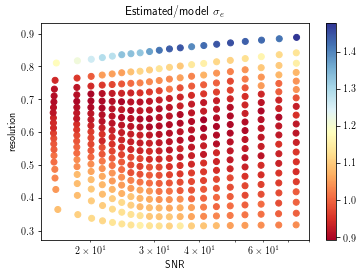

In [18]:
# model / estimated sigma_e as a function of SNR, resolution.  Should be close to 1.
fig = plt.figure()
ax = fig.add_subplot(111)
sc = ax.scatter(mean_snr, mean_res, c=est_sigma_e/model_sigma_e, cmap=cm)
plt.colorbar(sc)
ax.set_title(r'Estimated/model $\sigma_e$')
plt.xscale('log')
plt.xlabel('SNR')
plt.ylabel('resolution')
plt.savefig(os.path.join(pltDir,'sigmae_ratio.png'))

# save data table for model/actual
# which will be used to interpolate the residuals
out_data = (mean_snr.flatten(), mean_res.flatten(),
            (est_sigma_e/model_sigma_e).flatten())
out_data = np.column_stack(out_data)
np.savetxt(os.path.join(pltDir,'sigmae_ratio.dat'), out_data)

## Per-component $e_{\rm{rms}}$

$$e_{rms}=\sqrt{\frac{\sum_i w_i (e_{i,1}^2+e_{i,2}^2-2\sigma_e^2(\rm{snr}_i,\rm{res}_i))}{2\sum_i w_i}}$$
The aforementioned equation is based on the assumption that the measruement error is independent of the intrinsic shape of galaxies.

### Use Simulations

Text(0, 0.5, 'resolution')

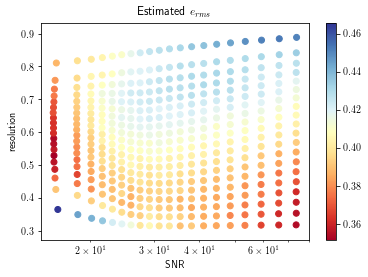

In [19]:
# Use the estimated sigma_e
# Plot estimated e_rms.
fig = plt.figure()
ax = fig.add_subplot(111)
vmin = np.min(est_rms)
vmax = np.max(est_rms)
sc = ax.scatter(mean_snr, mean_res, c=est_rms, cmap=cm,
                vmin=vmin, vmax=vmax)
plt.colorbar(sc)
ax.set_title(r'Estimated $e_{rms}$')
plt.xscale('log')
plt.xlabel('SNR')
plt.ylabel('resolution')
#plt.savefig(os.path.join(pltDir,'eRms_estimated.png'))

### Use Observation

In [ ]:
if False:
    data=pyfits.getdata('../../database/smallcat-wl-s19-2.fits')
    # WL cut for Observation
    # cancel_shape_noise MUST be true for this test
    # since we are applying it to observation

    min_snr=10
    max_snr=200
    max_magA10=25.5
    min_res=0.3
    max_mag=24.5
    max_logb=-0.38
    max_sigma_e=0.4
    max_e=2.
    wlmask    =   utilities.galaxy_selector(catalog=data,
                    min_snr=min_snr, #snr
                    max_snr=max_snr,
                    max_magA10=max_magA10, #magA10
                    min_res=min_res, #res
                    max_mag=max_mag, #mag
                    max_logb=max_logb,#logb
                    force_90_pair=False,# orthogonal pairs
                    max_e=max_e,     #absE
                    max_sigma_e=max_sigma_e) #sigma_e
    # Use the sigma_e mdoel
    data=data[wlmask]
    pyfits.writeto('../../database/smallcat-wl-s19-reGausOptimize.fits',data)
else:
    data=pyfits.getdata('../../database/smallcat-wl-s19-reGausOptimize.fits')

In [27]:
if True:
    # First: assemble the arrays for individual subfields into one big master catalog.
    master_e1 = data['e1_regaus']
    master_e2 = data['e2_regaus']
    master_sigma_e = data['sigma_e']
    master_resolution = data['res']
    master_snr = data['snr']
    master_weight = data['weight']
    master_model_sigma_e = utilities.get_sigma_e_model(data,pltDir=pltDir)

    # Then do the 2d estimation as a function of SNR and resolution.
    nbin_1d=30
    snr_lower, snr_upper, res_lower, res_upper = \
        utilities.sliding_window_def(master_snr, master_resolution,
                                     n_gal=200*100,n_bin_1d=nbin_1d)

    mean_snr = np.zeros((nbin_1d, nbin_1d))
    mean_res = np.zeros((nbin_1d, nbin_1d))
    cat_rms = np.zeros((nbin_1d, nbin_1d))
    model_rms = np.zeros((nbin_1d, nbin_1d))
    for i in range(len(snr_lower)):
        for j in range(len(snr_lower)):
            in_bin = \
                (master_snr >= snr_lower[i]) & \
                (master_snr < snr_upper[i]) & \
                (master_resolution >= res_lower[i,j]) & \
                (master_resolution < res_upper[i,j])
            cat_rms[i,j] = np.sqrt(0.5*np.sum(
                    master_weight[in_bin]*\
                        (master_e1[in_bin]**2+master_e2[in_bin]**2-2*master_sigma_e[in_bin]**2)) / \
                                       np.sum(master_weight[in_bin]))
            model_rms[i,j] = np.sqrt(0.5*np.sum(
                    master_weight[in_bin]*\
                        (master_e1[in_bin]**2+master_e2[in_bin]**2-2*master_model_sigma_e[in_bin]**2)) / \
                                         np.sum(master_weight[in_bin]))
            mean_snr[i,j] = \
                np.sum(master_weight[in_bin]*master_snr[in_bin])/np.sum(master_weight[in_bin])
            mean_res[i,j] = \
                np.sum(master_weight[in_bin]*master_resolution[in_bin])/np.sum(master_weight[in_bin])
    out_rms={'mean_snr':mean_snr,'mean_res':mean_res,'cat_rms':cat_rms,'model_rms':model_rms}
    np.save(os.path.join(pltDir,'intrinsicshape.npy'),out_rms)
else:
    out_rms=np.load(os.path.join(pltDir,'intrinsicshape.npy')).item()
    mean_snr=out_rms['mean_snr']
    mean_res=out_rms['mean_res']
    cat_rms=out_rms['cat_rms']
    model_rms=out_rms['model_rms']

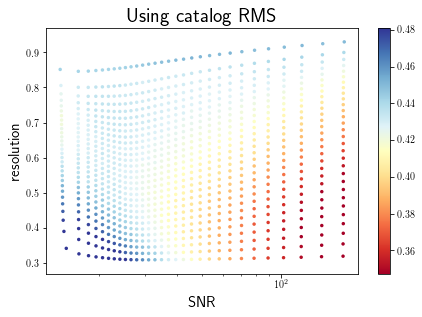

In [28]:
# e_rms estimated with sigma_e estimated with LSST pipeline
cm = plt.cm.get_cmap('RdYlBu')
vmin = np.quantile(cat_rms,0.02)
vmax = np.quantile(cat_rms,0.98)
fig = plt.figure()
ax = fig.add_subplot(111)
sc = ax.scatter(mean_snr, mean_res, c=cat_rms, cmap=cm,
    vmin=vmin, vmax=vmax, edgecolors='none',s=12.)
#ax.set_xlim(left=10., right=200.)
plt.colorbar(sc)
plt.tight_layout()
ax.set_title('Using catalog RMS',fontsize=20)
plt.xscale('log')
plt.xlabel('SNR',fontsize=15)
plt.ylabel('resolution',fontsize=15)
plt.savefig(os.path.join(pltDir,'intrinsicshape_cat_2d.png'))

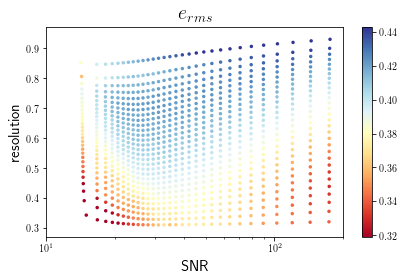

In [29]:
# e_rms estimated with sigma_e estimated with orthorgonal galaxies pairs
fig = plt.figure()
vmin = np.quantile(model_rms,0.01)
vmax = np.quantile(model_rms,0.99)
ax = fig.add_subplot(111)
sc = ax.scatter(mean_snr, mean_res, c=model_rms, cmap=cm,
    vmin=vmin, vmax=vmax, edgecolors='none',s=12)
ax.set_xlim(left=10., right=200.)
cbar = plt.colorbar(sc)
plt.xscale('log')
plt.xlabel('SNR',fontsize=15)
plt.ylabel('resolution',fontsize=15)
plt.title(r'$e_{rms}$',fontsize=20)
plt.tight_layout()
plt.savefig(os.path.join(pltDir,'intrinsicshape_2d.png'))
plt.savefig(os.path.join(pltDir,'intrinsicshape_2d.eps'))

# save data table for model/actual
out_data = (mean_snr.flatten(), mean_res.flatten(),
            model_rms.flatten())
out_data = np.column_stack(out_data)
np.savetxt(os.path.join(pltDir,'intrinsicshape_2d.dat'), out_data)

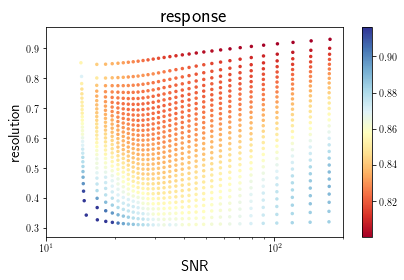

In [33]:
# response estimated
fig = plt.figure()
vmin = np.quantile(1-model_rms**2.,0.005)
vmax = np.quantile(1-model_rms**2.,0.995)
ax = fig.add_subplot(111)
sc = ax.scatter(mean_snr, mean_res, c=1-model_rms**2., cmap=cm,
    vmin=vmin, vmax=vmax, edgecolors='none',s=12)
ax.set_xlim(left=10., right=200.)
cbar = plt.colorbar(sc)
plt.xscale('log')
plt.xlabel('SNR',fontsize=15)
plt.ylabel('resolution',fontsize=15)
plt.title('response',fontsize=20)
plt.tight_layout()